# RadioSkySims — Simulação de TOD (leve)

Pipeline de geração de Time-Ordered Data (TOD) do RadioSkySim **desacoplado**
(`radioskysims_simulation`), usando a API `SimOrchestrator` e o perfil
`default` do `settings.toml`.

Este notebook é uma **simulação leve**: janela de 1 h (passo 60 s), apenas GPS,
com `use_processor=True` para batches seguros de memória. Valida o ciclo
**satélites → TOD → persistência** sem travar a máquina (a versão com 24 h e
4 constelações sobrecarregou o ambiente anteriormente).

Fluxo:
1. Parâmetros de referência (leves)
2. Radiotelescópio (`default`) e orquestrador
3. Satélites GPS com PRN (refatoração NORAD ↔ Nome ↔ PRN)
4. Simulação TOD discreta (GPS)
5. Persistência HDF5/NetCDF + reload (ciclo "ida e volta")


## 1. Parâmetros de referência (leves)

Janela curta (1 h, passo 60 s) e observador do radiotelescópio `default`.
A data de referência é 1 mês antes de agora (UTC).


In [1]:
# ── Âncora de diretório: raiz do projeto (CWD-independente) ──
# Garante que caminhos relativos (ex.: Path("data")/TOD) resolvam da raiz do
# projeto, independente de onde o kernel Jupyter iniciou (notebooks/ ou raiz).
import os

from radioskysims_core.paths import get_project_root

os.chdir(get_project_root())
print("cwd →", os.getcwd())

cwd → /share/lbarosi/RadioSkySimSuite


In [2]:
# ── Parâmetros de referência para a simulação leve ──
from datetime import UTC, datetime, timedelta
from pathlib import Path

import numpy as np  # noqa: F401

from radioskysims import create_radiotelescope
from radioskysims_core.domain.common import FrequencyRange, TimeRange

# Data de referência: 1 mês antes de agora (UTC).
REF_DATE = (datetime.now(UTC) - timedelta(days=30)).replace(microsecond=0)
print("Data de referência (REF_DATE):", REF_DATE.isoformat())

# Janela LEVE: 1 h a partir de REF_DATE, passo de 60 s.
_ISO = "%Y-%m-%dT%H:%M:%S"
TR = TimeRange.from_iso(
    REF_DATE.strftime(_ISO),
    (REF_DATE + timedelta(minutes=60)).strftime(_ISO),
    60,
)
print("TimeRange (1 h, 60 s):", TR.to_datetime64().shape[0], "instantes")

FR = FrequencyRange(min_mhz=1000.0, max_mhz=1250.0, resolution_mhz=0.5)

# Observador do radiotelescópio (perfil default em settings.toml).
uirapuru = create_radiotelescope("default")
OBSERVER = uirapuru.observer
print("Observador:", OBSERVER)

# Diretório de saída.
TOD_DIR = Path("data") / "TOD"
TOD_DIR.mkdir(parents=True, exist_ok=True)


Data de referência (REF_DATE): 2026-10-08T05:50:04+00:00
TimeRange (1 h, 60 s): 61 instantes
Observador: lat=<Angle -7.211637 deg> lon=<Angle -35.90813 deg> height=<Quantity 530. m> timeframe=<TimeRange 2025-02-27 00:00:00.000 to 2025-02-28 00:00:00.000 | resolution=120.0s>


In [3]:
# ── Compatibilidade com async em notebooks ──
# Permite que wrappers síncronos (ex.: asyncio.run no refresh de TLEs do
# SpaceTrack/CelesTrak) rodem dentro do event loop do Jupyter.
import nest_asyncio

nest_asyncio.apply()
print("✅ nest_asyncio aplicado")

# ── Credenciais locais (SpaceTrack/CIRADA) no processo atual ──
# satellite_downloader carrega credentials.env no import do módulo; como o
# kernel já importou os módulos antes do arquivo existir, recarregamos aqui
# para o refresh de TLEs funcionar sem reiniciar o kernel.
import os

from dotenv import load_dotenv
from radioskysims_core.paths import get_project_root

load_dotenv(get_project_root() / "credentials.env", override=False)
print("✅ credentials.env carregado — ST_USER presente:", bool(os.getenv("ST_USER")))

✅ nest_asyncio aplicado
✅ credentials.env carregado — ST_USER presente: True


In [4]:
# ── Orquestrador de simulação (composition root completo) ──
# `create_sim_orchestrator` injeta também o processor_factory (DIContainer),
# necessário para `use_processor=True` — `SimOrchestrator.from_settings` NÃO
# injeta a factory e falharia com "Processor não injetado...".
from radioskysims_simulation.bootstrap.composition import create_sim_orchestrator

orch = create_sim_orchestrator(telescope="default")
print("✅ Orquestrador configurado")
print("Constelações padrão (settings):", orch.default_constellations())
print("Time range padrão (settings):", orch.default_time_range())


✅ Orquestrador configurado
Constelações padrão (settings): ['GPS', 'GALILEO', 'BEIDOU', 'GLONASS']
Time range padrão (settings): start_jd=2460733.5 end_jd=2460734.5 resolution_sec=120.0


In [5]:
# ── Data providers ativos (composition root dos facades UX) ──
# Registra as fábricas concretas dos providers: track local (Skyfield), PSD de
# sinais (gnsstools), ingest TAP VizieR e repositórios PostgreSQL.
# Necessário ANTES de usar SatelliteOrchestrator/RadioSourcesManager sem
# injeção manual — senão `_psd_provider()` levanta
# "PSD provider de sinais não configurado".
from radioskysims_sources.bootstrap.builders import configure_facade_defaults

configure_facade_defaults()
print("✅ Data providers registrados (configure_facade_defaults)")


✅ Data providers registrados (configure_facade_defaults)


## 2. Satélites GPS com PRN

A refatoração integrou o mapeamento **NORAD ↔ Nome ↔ PRN** ao modelo persistido
(ver `radioskysims-sources`, branch `feature/satellite-prn-mapping`). Cada
satélite agora expõe `prn` e `sv` (ex.: `G22`), facilitando a comparação com
RINEX e com o catálogo de sinais.


In [6]:
# ── Satélites GPS via SatelliteOrchestrator (TLE do banco) ──
# Fachada pública: esconde Database/build_repositories/SatelliteManager.
from radioskysims_sources import SatelliteOrchestrator

sat_orch = SatelliteOrchestrator.create_from_constellation(
    "GPS",
    epoch=REF_DATE,
)
sats = sat_orch.satellites
print(f"✅ {len(sats)} satélites GPS carregados (TLE na época de referência)")

# NORAD ↔ Nome ↔ PRN (integrado ao modelo persistido).
print(f"{'NORAD':>8} | {'Nome':<28} | {'PRN':>4} | SV")
for sat in sats[:10]:
    prn = sat.prn if sat.prn is not None else None
    sv = sat.sv if sat.prn is not None else None
    print(
        f"{sat.norad_id:>8} | {sat.name:<28} | "
        f"{prn if prn is not None else '—':>4} | {sv if sv is not None else '—'}"
    )


✅ 32 satélites GPS carregados (TLE na época de referência)
   NORAD | Nome                         |  PRN | SV
   26407 | GPS BIIR-5 (PRN 22)          |   22 | G22
   27663 | GPS BIIR-8 (PRN 16)          |   16 | G16
   28190 | GPS BIIR-11 (PRN 19)         |   19 | G19
   28474 | GPS BIIR-13 (PRN 02)         |    2 | G02
   28874 | GPS BIIRM-1 (PRN 17)         |   17 | G17
   29486 | GPS BIIRM-2 (PRN 31)         |   31 | G31
   29601 | GPS BIIRM-3 (PRN 12)         |   12 | G12
   32260 | GPS BIIRM-4 (PRN 15)         |   15 | G15
   32384 | GPS BIIRM-5 (PRN 29)         |   29 | G29
   32711 | GPS BIIRM-6 (PRN 07)         |    7 | G07


## 3. Simulação TOD (discreta, leve)

Gera o TOD dos satélites GPS sobre o pointing do `default`, usando o
`ResourceAwareProcessor` (`use_processor=True`) para batches seguros de memória.
O dataset permanece **lazy (dask)** — não materializamos o TOD completo em RAM.


In [7]:
# ── Simulação TOD discreta (GPS, janela de 1 h) ──
import time

t0 = time.monotonic()
result = orch.run(
    constellations=["GPS"],
    time_range=TR,
    include_satellites=True,
    include_local_sources=False,
    include_radio_sources=False,
    use_processor=True,
)
print(f"⏱ run() completou em {time.monotonic() - t0:.1f}s")

ds = result.simulation_result.dataset
print("dims:", dict(ds.sizes))
print("variáveis:", list(ds.data_vars))

# Resumo (lazy-safe — não computa o dataset completo).
print(result.format_summary()[:1200])


⏱ run() completou em 25.9s
dims: {'time': 61, 'frequency': 5000, 'polarization': 4, 'source': 32, 'pointing': 1}
variáveis: ['T_antenna', 'power']
════════════════════════════════════════════════════════════════════════
  RADIOSKYSIM — RESUMO DA SIMULAÇÃO
════════════════════════════════════════════════════════════════════════

┌─ OBSERVER ──────────────────────────────────────────────
  Nome                    : default
  Localização (lat/lon)    : -7.21 / -35.91  (height 530 m)
  Frequency Range (MHz)    : 1000 → 1250  (n_channels=5000)
  Central Frequency (MHz) : 1125
  Antenna                 : BINGO Horn
    Pointing (Alt/Az)      : 65.00° / 0.00°
    Polarizations         : ['H_COPOL']
    Beam FWHM (deg)       : min 9.5 / med — / max 18.75
    Directivity (dBi)     : min 18.4437 / med — / max 25.6479

┌─ SIMULATION ─────────────────────────────────────────────
  Timerange (UTC)         : 2026-10-08T05:50:04.000 → 2026-10-08T06:50:04.000  (step 60 s)
  Sky ─ Satellites:
    - GPS

In [8]:
# ── Persistência + reload (ciclo "ida e volta") ──
from radioskysims_simulation.domain.simulation import (
    SimulationOrchestratorResult,
)

out = str(TOD_DIR / "gps_tod_leve.nc")
sidecar = result.save_result(out)
print("Salvo dataset:", out)
print("Sidecar JSON :", sidecar)

# Reload sem re-rodar a simulação:
loaded = SimulationOrchestratorResult.load_result(out)
print("Reload OK. Resumo:")
print(loaded.format_summary()[:600])


Salvo dataset: data/TOD/gps_tod_leve.nc
Sidecar JSON : data/TOD/gps_tod_leve.nc.json
Reload OK. Resumo:
════════════════════════════════════════════════════════════════════════
  RADIOSKYSIM — RESUMO DA SIMULAÇÃO
════════════════════════════════════════════════════════════════════════

┌─ OBSERVER ──────────────────────────────────────────────
  Nome                    : default
  Localização (lat/lon)    : -7.21 / -35.91  (height 530 m)
  Frequency Range (MHz)    : 1000 → 1250  (n_channels=5000)
  Central Frequency (MHz) : 1125
  Antenna                 : BINGO Horn
    Pointing (Alt/Az)      : 65.00° / 0.00°
    Polarizations         : ['H_COPOL']
    Beam FWHM (deg)       : min 9.5 / med — / 


## 4. Ciclo ida e volta de mapas (leve)

Fechamos o ciclo **mapas → TOD → mapas** usando as APIs públicas do
RadioSkySim. Em vez da banda completa do `default` — que pode gerar milhares
de mapas PySM3 — usamos uma **banda reduzida de 2 canais** e `nside=8`,
mantendo o exemplo rápido e reprodutível.

Fluxo:

1. **Ida**: mapas galácticos (PySM3) → projeção no pointing de trânsito do
   radiotelescópio → TOD difuso `(time, frequency)`, usando
   `SimOrchestrator.run_maps()`.
2. **Volta**: `MapMakingOrchestrator` reconstrói um mapa HEALPix por canal a
   partir do TOD + pointing.
3. **Validação**: comparação entre o mapa de entrada e o reconstruído nos
   pixels observados.

A fachada `SimOrchestrator.run_maps()` mantém o projector HEALPix→TOD
encapsulado no composition root; o usuário precisa fornecer apenas os mapas,
o pointing e a opção de convolução com o beam.


In [9]:
# ── Ida: mapas galácticos (PySM3) via ContinuumSourceOrchestrator ──
import time

from radioskysims_core.domain.common import FrequencyRange
from radioskysims_sources import ContinuumSourceOrchestrator
from radioskysims_sources.domain.radiosources.continuum import Galaxy

# Banda leve: 2 canais (1000 e 1250 MHz) em vez da banda completa do uirapuru.
GAL_FR = FrequencyRange(min_mhz=1000.0, max_mhz=1250.0, resolution_mhz=250.0)
NSIDE = 8

continuum = ContinuumSourceOrchestrator.default()
t0 = time.monotonic()
galaxy_mapset = continuum.galaxy_maps(
    source=Galaxy(),
    frequency_range=GAL_FR,
    nside=NSIDE,
    persist=True,  # grava HDF5 em data/aux/skymaps (galaxy_<freq>mhz_nside<n>)
    overwrite=True,
)
print(
    f"✅ {len(galaxy_mapset.maps)} mapas galácticos PySM3 (nside={NSIDE}) "
    f"em {time.monotonic() - t0:.1f}s"
)

for sky in galaxy_mapset.maps:
    print(
        f"  {sky.freq_ghz:.3f} GHz | {sky.unit} | frame={sky.frame} | "
        f"mean={float(sky.data.mean()):.3e}"
    )


✅ 2 mapas galácticos PySM3 (nside=8) em 7.6s
  1.000 GHz | uK_CMB | frame=galactic | mean=2.097e+06
  1.250 GHz | uK_CMB | frame=galactic | mean=1.108e+06


In [10]:
# ── Ida: pointing de trânsito + projeção pública mapas → TOD ──
from radioskysims_core.domain.geometry import compute_pointing_track

time_grid = TR.to_datetime64()

pointing = compute_pointing_track(
    observer=OBSERVER,
    time_grid=time_grid,
    alt_deg=65.0,
    az_deg=0.0,
)

print(
    "Pointing track:",
    len(pointing.time),
    "instantes | ra0:",
    float(pointing["ra"].values[0]),
    "deg",
)

t0 = time.monotonic()

diffuse_tod = orch.run_maps(
    maps=galaxy_mapset.maps,
    pointing_track=pointing,
    use_beam=True,
).compute()

print(f"✅ TOD difuso (mapas → TOD) em {time.monotonic() - t0:.1f}s")
print("dims:", dict(diffuse_tod.sizes), "| vars:", list(diffuse_tod.data_vars))
print(
    "T_antenna média por canal (K):",
    diffuse_tod.T_antenna.mean("time").values.round(4),
)


Pointing track: 61 instantes | ra0: 68.10345368740855 deg
✅ TOD difuso (mapas → TOD) em 0.3s
dims: {'time': 61, 'frequency': 2} | vars: ['T_antenna', 'power']
T_antenna média por canal (K): [2.0581 1.0883]


In [11]:
# ── Volta: TOD → mapas (binned HEALPix) via MapMakingOrchestrator ──
from radioskysims_simulation import MapMakingOrchestrator

mapmaking = MapMakingOrchestrator.default()
t0 = time.monotonic()
mk_result = mapmaking.run(
    tod=diffuse_tod,  # TOD difuso (time, frequency) em K
    pointing_track=pointing,
    nside=NSIDE,
    frame="equatorial",
)
print(
    f"✅ Mapas reconstruídos (TOD → mapas) em {time.monotonic() - t0:.1f}s "
    f"({len(mk_result.mapmaking.results)} canais)"
)

for rec in mk_result.mapmaking.results:
    sky = rec.skymap
    print(
        f"  {sky.freq_ghz:.3f} GHz | frame={sky.frame} | "
        f"n_obs={int(rec.observed_mask.sum())} "
        f"| coverage={rec.coverage_fraction:.3f} | "
        f"mean_obs={float(sky.data[rec.observed_mask].mean()):.4f} K"
    )


✅ Mapas reconstruídos (TOD → mapas) em 0.0s (2 canais)
  1.000 GHz | frame=equatorial | n_obs=4 | coverage=0.005 | mean_obs=2.0707 K
  1.250 GHz | frame=equatorial | n_obs=4 | coverage=0.005 | mean_obs=1.1052 K


In [12]:
# ── Validação: mapa de entrada (galáctico) × mapa reconstruído (equatorial) ──
import healpy as hp
import numpy as np

# Mapa reconstruído do canal 1000 MHz está em coordenadas equatoriais.
rec0 = mk_result.mapmaking.results[0]
obs_pix = np.where(rec0.observed_mask)[0]

# Direções (equatoriais) dos pixels observados → coordenadas galácticas.
rot = hp.Rotator(coord=["C", "G"])
theta_eq, phi_eq = hp.pix2ang(NSIDE, obs_pix, nest=False)
theta_g, phi_g = rot(theta_eq, phi_eq)

# Amostra o mapa galáctico de ENTRADA nas mesmas direções (uK_CMB → K).
gal0 = galaxy_mapset.maps[0]
input_k = hp.get_interp_val(gal0.data * 1e-6, theta_g, phi_g)
output_k = rec0.skymap.data[obs_pix]

corr = float(np.corrcoef(input_k, output_k)[0, 1])
mae = float(np.mean(np.abs(input_k - output_k)))

print(f"Pixels observados: {len(obs_pix)}")
print(f"Correlação (entrada vs reconstruído): {corr:.3f}")
print(f"Erro médio absoluto (MAE): {mae:.4f} K")
print(
    f"\nCiclo ida e volta OK — mapas → TOD → mapas "
    f"(banda {GAL_FR.value[0]:.0f}–{GAL_FR.value[-1]:.0f} MHz, nside={NSIDE})"
)

Pixels observados: 4
Correlação (entrada vs reconstruído): 0.928
Erro médio absoluto (MAE): 0.1995 K

Ciclo ida e volta OK — mapas → TOD → mapas (banda 1000–1250 MHz, nside=8)


## 5. Visualizações — mapas + TOD (waterfall)

Fechamos com a camada de visualização sobre os produtos das seções 3 e 4:

1. **Mapas**: Mollweide do mapa galáctico de **entrada** (PySM3, `uK_CMB`) e do
   mapa equatorial **reconstruído** pelo *mapmaking* (`K`), via `SkyMapVisualizer`
   (`radioskysims-skymap`) com `save_figure` (`radioskysims-viz`).
2. **TOD → Waterfall**: o TOD dos satélites GPS (seção 3) é reduzido a uma grade
   tempo × frequência (soma sobre fontes, polarização `H_COPOL`) e empacotado
   como `Waterfall` (`radioskysims-waterfall`). Aplicamos limpeza leve
   (`WaterfallPipeline`: filtro espectral + normalização min-max) e mostramos o
   waterfall interativo + espectro médio (SED) e curva de luz.

Mapa entrada: 1.0 GHz | uK_CMB | frame = galactic | nside = NSide(8)
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sims_map_galaxy_input.png
Mapa reconstruído: 1.0 GHz | K | frame = equatorial | n_obs = 4
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sims_map_reconstructed.png
✅ figuras salvas em notebooks/plots/ (sims_map_*)


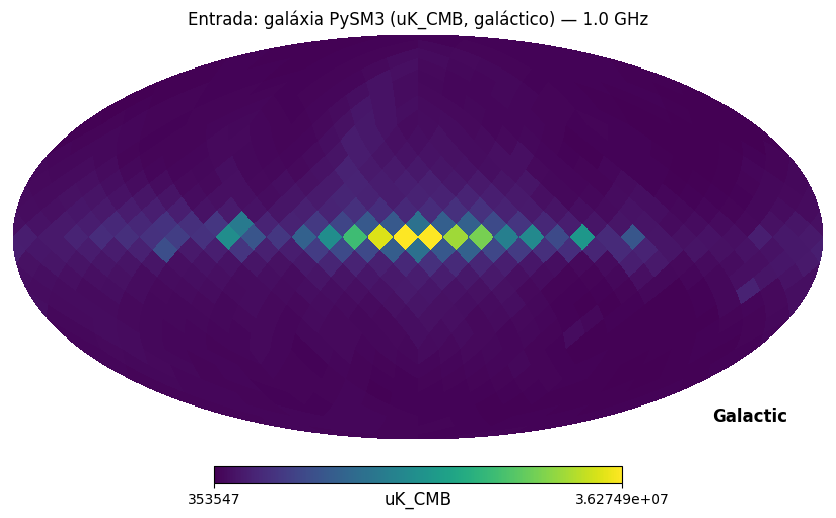

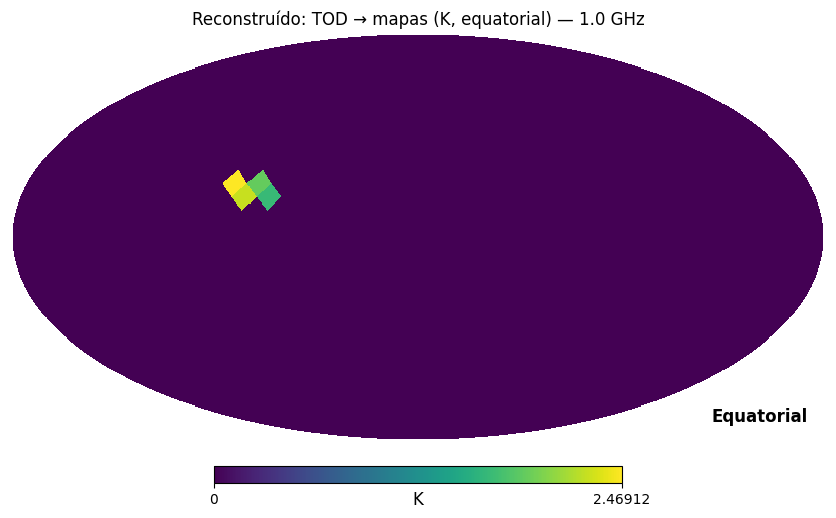

In [13]:
# ── Visualização: mapas de entrada e reconstruídos (Mollweide) ──
%matplotlib inline
import matplotlib.pyplot as plt

from radioskysims_skymap.infrastructure.skymap.visualization import SkyMapVisualizer
from radioskysims_viz import save_figure

vis = SkyMapVisualizer()

# Mapa de ENTRADA (galáctico, uK_CMB) — canal 1.0 GHz
gal0 = galaxy_mapset.maps[0]
print(
    "Mapa entrada:",
    gal0.freq_ghz,
    "GHz |",
    gal0.unit,
    "| frame =",
    gal0.frame,
    "| nside =",
    gal0.nside,
)
vis.plot_map(gal0, show=False, coord="G")
plt.title("Entrada: galáxia PySM3 (uK_CMB, galáctico) — 1.0 GHz")
save_figure(plt.gcf(), "sims_map_galaxy_input")

# Mapa RECONSTRUÍDO (equatorial, K) — canal 1.0 GHz
rec0 = mk_result.mapmaking.results[0]
print(
    "Mapa reconstruído:",
    rec0.skymap.freq_ghz,
    "GHz |",
    rec0.skymap.unit,
    "| frame =",
    rec0.skymap.frame,
    "| n_obs =",
    int(rec0.observed_mask.sum()),
)
vis.plot_map(rec0.skymap, show=False, coord="C")
plt.title("Reconstruído: TOD → mapas (K, equatorial) — 1.0 GHz")
save_figure(plt.gcf(), "sims_map_reconstructed")

print("✅ figuras salvas em notebooks/plots/ (sims_map_*)")

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
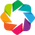

TOD 2D (time, freq): (61, 5000) | faixa (K): 0.0 — 1213.3492
Waterfall após pipeline: (61, 5000) | faixa (norm.): 0 — 1


:Layout
   .Curve.I  :Curve   [Frequência (MHz)]   (T_antenna (norm.))
   .Curve.II :Curve   [time]   (T_antenna)

In [14]:
# ── Visualização: TOD → Waterfall (tempo × frequência) dos satélites GPS ──
import holoviews as hv
import numpy as np

from radioskysims_waterfall import Waterfall, WaterfallMetadata, WaterfallPipeline

hv.extension("bokeh")

# TOD 2D: soma sobre fontes, polarização H_COPOL, remove pointing → (time, freq)
ta = result.simulation_result.dataset.T_antenna
tod2d = (
    ta.sel(polarization="H_COPOL")
    .sum("source")
    .isel(pointing=0, drop=True)
    .transpose("time", "frequency")
)
print(
    "TOD 2D (time, freq):",
    tod2d.shape,
    "| faixa (K):",
    round(float(tod2d.min()), 4),
    "—",
    round(float(tod2d.max()), 4),
)

wf = Waterfall(
    tod2d,
    time_name="time",
    freq_name="frequency",
    meta=WaterfallMetadata(
        name="gps_tod_leve",
        instrument="UIRAPURU / BINGO Horn",
        band="1000-1250 MHz",
        polarization="H_COPOL",
        data_unit="K",
        freq_unit="Hz",
    ),
)

# Limpeza leve para visualização (filtro espectral + normalização min-max).
pipe = WaterfallPipeline()
pipe.add("filter_spectral", method="median", window=3)
pipe.add("normalize", method="minmax")
wfc = pipe.run(wf)
print("Waterfall após pipeline:", wfc.shape, "| faixa (norm.): 0 — 1")

# Grade para plot (frequência em MHz).
wf_img = wfc.data.rename(freq="freq_MHz").assign_coords(freq_MHz=wfc.data["freq"].values / 1e6)

waterfall_plot = hv.Image(wf_img, kdims=["freq_MHz", "time"]).opts(
    colorbar=True,
    cmap="viridis",
    width=760,
    height=300,
    title="Waterfall GPS — T_antenna (H_COPOL, soma fontes, norm.)",
    xlabel="Frequência (MHz)",
    ylabel="Tempo (UTC)",
)
waterfall_plot

# Espectro médio (SED) e curva de luz (perfil temporal médio na banda).
sed = wfc.data.mean("time")
lc = wfc.data.mean("freq")
sed_curve = hv.Curve(
    (sed["freq"].values / 1e6, sed.values),
    kdims="Frequência (MHz)",
    vdims="T_antenna (norm.)",
).opts(width=760, height=240, title="SED — T_antenna média no tempo")
lc_curve = hv.Curve(lc).opts(width=760, height=220, title="Curva de luz — média na banda (norm.)")
sed_curve + lc_curve

## 6. Próximos passos (modos pesados / opcionais)

A seção 5 demonstrou as visualizações de **mapas** (Mollweide) e **TOD
(waterfall)** em modo leve. Os itens abaixo usam a banda completa ou fontes
extras e devem ser ligados apenas quando houver recurso:

- **Galáxia (PySM3) em banda completa**: `orch.run(include_galaxy=True, galaxy_nside=64, persist_skymaps=True)` → ~5001 mapas HEALPix no default do `default` (parte pesada; por padrão desligada).
- **NVSS**: `include_radio_sources=True` com filtro pela declinação do pointing.
- **Comparação TLE vs RINEX**: mesmo satélite nos dois tracks (`gnsstools4astro`).
- **Waterfall com eventos**: grade de eventos/bandpass do `radioskysims_waterfall` sobre TOD longos.

### 6.1 API de alto nível alvo (Anexo A) — status por contexto

Fachadas/orquestradores por contexto (ver `notebooks/ux_entrypoints_audit.md`, Anexo A). Conveniências marcadas como **pendente** ainda não estão implementadas (roadmap).

- **Satélites** — `SatelliteOrchestrator` (TLE via banco). Carregamento por `method="RINEX"`/`from_RINEX()` (via `gnsstools4astro`) **pendente**.
- **Fontes locais** — `LocalSourcesOrchestrator.create_sun()`.
- **Fontes de rádio** — `RadioSourcesOrchestrator` (catálogo / simulado / TAP).
- **Contínuo** — `ContinuumSourceOrchestrator` (PySM3).
- **SkyMap** — `SkyMapOrchestrator` + `Mask`. A conveniência `from_sources()` permanece pendente. A projeção mapa→TOD pertence ao contexto de simulação e é exposta por `SimOrchestrator.run_maps()`.
- **Simulação** — `SimOrchestrator`, incluindo `run_maps()` para projeção de mapas difusos em TOD.
- **Mapmaking** — `MapMakingOrchestrator`, responsável pelo fluxo TOD→mapa HEALPix.
- **Waterfall** — `Waterfall` (`radioskysims-waterfall`).
